In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("books_dataset.csv")
df.head(1) # display only one row, just to confirm successful import

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...


In [ ]:
#===== Understanding the dataset ==========

print("Rows:", len(df))
print('-'*40)
print("Columns:", len(df.columns))
print('-'*40)
print("Missing values\n", df.isnull().sum())
print('-'*40)
print("Data-Types\n", df.dtypes)
print('-'*40)
print("Data-Description\n", df.describe())
print('-'*40)
print("Data-info", df.info())

In [29]:
#===== Analytical Questions ==========

df["Price"].mean() # Average Price
df["Price"].median() # Median Price
df["Price"].min() # Price of the Cheapest Book
df["Price"].max() # Price of the Most Expensive Book

#----- Identifying the Books -----

df.loc[df["Price"].idxmin()] # Cheapest Book
df.loc[df["Price"].idxmax()] # Most Expensive Book

#----- Investigate rating: how the books are distributed across rating Categories ------

df["Rating"].value_counts()
df["Rating"].value_counts(normalize=True) * 100 # Percentage by Rating

"""
Are highly rated books more expensive?
i can investigate this.
First, i converted the rating words to numbers:

"""

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating_Numeric"] = df["Rating"].map(rating_map)
df["Rating_Numeric"] = df["Rating"].map(rating_map).head() 
df[["Rating", "Rating_Numeric"]].head(10) # Check by displaying only 10
df.groupby("Rating_Numeric")["Price"].mean() # # I Checked if Rating is Affected by Price

"""
Rating
1 - average price
2 - average price
3 - average price
4 - average price
5 - average price

"""
#----- Identifying the Most Expensive and Cheapest Book------

#--- TOP 10 Most Expensive Book ----
df.nlargest(10, "Price")[["Title", "Price", "Rating"]] # Most Expensive Book

#--- TOP 10 Most Cheapest Book ----
df.nsmallest(10, "Price")[["Title", "Price", "Rating"]] # Cheapest Book

# This helped me investigate whether there are unusual prices or potential outliers

,Title,Price,Rating
638,An Abundance of Katherines,10.00,Five
501,The Origin of Species,10.01,Four
716,The Tipping Point: How Little Things Can Make ...,10.02,Two
84,Patience,10.16,Three
302,Greek Mythic History,10.23,Five
558,The Fellowship of the Ring (The Lord of the Ri...,10.27,Two
479,History of Beauty,10.29,Four
242,The Lucifer Effect: Understanding How Good Peo...,10.40,One
434,"NaNo What Now? Finding your editing process, r...",10.41,Four
274,Pet Sematary,10.56,Three


In [48]:
"""
Measure the Relationship.....

i calculated the correlation.

"""

correlation = df["Rating_Numeric"].corr(df["Price"])

if correlation < 0:
    print(f"The Correlation between rating and price is Negative : {correlation}")
elif correlation == 0:
    print(f"The Correlation between rating and price is Neutral : {correlation}")
else:
    print(f"The Correlation between rating and price is Positive : {correlation}, Indicating ")


The Correlation between rating and price is Negative : -0.11095021590096944


In [49]:
#----- Detect Price Outliers------

# I used the IQR method.
#First:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)


Q1: 22.1075
Q3: 47.457499999999996
IQR: 25.349999999999994
Lower bound: -15.91749999999999
Upper bound: 85.48249999999999


In [51]:
#-- find the potential outliers:
outliers = df[
    (df["Price"] < lower_bound) |
    (df["Price"] > upper_bound)
]

print("Number of potential price outliers:", len(outliers))

#--- inspecting them if any exist
outliers[["Title", "Price", "Rating"]]

Number of potential price outliers: 0


,Title,Price,Rating


In [52]:
#-- Checking Availability:

df["Availability"].value_counts()

Availability
In stock    1000
Name: count, dtype: int64

In [53]:
# =========== FINAL EDA CHECK ================

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (1000, 6)

Missing values:
Title               0
Price               0
Rating              0
Availability        0
URL                 0
Rating_Numeric    990
dtype: int64

Duplicate rows:
0

Data types:
Title                 str
Price             float64
Rating                str
Availability          str
URL                   str
Rating_Numeric    float64
dtype: object


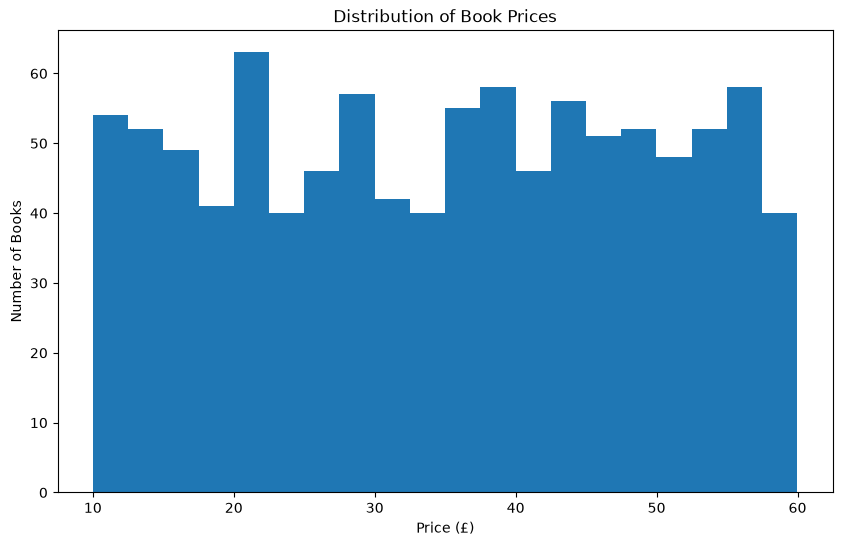

In [37]:
# =========== VISUALIZATION ================
# --- Price Distribution ------

plt.figure(figsize=(10, 6))

plt.hist(df["Price"], bins=20)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

# proper and more polished visualization will be done in task 3


In [55]:
# EDA Findings and Insights

print("========= EDA SUMMARY =========")

print(f"Total books: {len(df)}")

print(f"Average price: £{df['Price'].mean():.2f}")
print(f"Median price: £{df['Price'].median():.2f}")
print(f"Minimum price: £{df['Price'].min():.2f}")
print(f"Maximum price: £{df['Price'].max():.2f}")

print("\nMost common rating:")
print(df["Rating"].value_counts().idxmax())

print("\nRating distribution:")
print(df["Rating"].value_counts())

print("\nAverage price by rating:")
print(df.groupby("Rating_Numeric")["Price"].mean().round(2))

print(f"\nRating-Price correlation: {df['Rating_Numeric'].corr(df['Price']):.3f}")

print(f"\nNumber of potential price outliers: {len(outliers)}")

print("\nAvailability:")
print(df["Availability"].value_counts())

print(f"Duplicate rows: {df.duplicated().sum()}")

========= EDA SUMMARY =========
Total books: 1000
Average price: £35.07
Median price: £35.98
Minimum price: £10.00
Maximum price: £59.99

Most common rating:
One

Rating distribution:
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Average price by rating:
Rating_Numeric
1.0    44.66
3.0    34.85
4.0    34.59
5.0    54.23
Name: Price, dtype: float64

Rating-Price correlation: -0.111

Number of potential price outliers: 0

Availability:
Availability
In stock    1000
Name: count, dtype: int64
Duplicate rows: 0
